# Lab L3-3：從零寫一個小擴散模型（DDPM）（D3-3）

**需求單 #D3-3**（虛構公司：曜嶼電子，行銷部）：GAN 生成器畫的型錄縮圖變化不夠，要不要改用擴散模型？
我們用 Fashion-MNIST 當「商品縮圖」，自己寫一個小 DDPM，和 D3-1 的 DCGAN 比**多樣性**與**速度**。

| 步驟 | 做什麼 | 輸出 |
|---|---|---|
| A | 先看結果：現成的 DDPM（CIFAR-10，32 × 32）畫 16 張圖並計時 | `try_pretrained.png`、秒數 |
| B | 往前加噪：一張衣服，從 t＝0 到 t＝999 | `forward_strip.png`、`schedule.png` |
| C | 去噪網路：D2-2 的 U-Net ＋ 時間嵌入 | 每一塊的 shape |
| D | 訓練：預測雜訊（MSE） | `loss.png`、檢查點 |
| E | 取樣：從純雜訊走 1000 步回來；和 DCGAN 比多樣性 | `samples.png`、`reverse_strip.png`、兩兩距離 |
| F | 少走幾步：DDIM 的步數 vs 時間 | `ddim_steps.png` |
| G | 風險：生成的圖是不是「背下來」的訓練圖？ | `nearest.png` |

> 執行階段請選 **T4 GPU**。所有圖和數字最後會存進 `lab11_outputs.zip`。

In [31]:
# 第 1 格：環境
%pip install -q diffusers
import torch, os, math, time, json, random, platform
import numpy as np
import matplotlib.pyplot as plt
import diffusers
print("torch", torch.__version__, "| diffusers", diffusers.__version__, "| python", platform.python_version())
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    free, total = torch.cuda.mem_get_info()
    print("GPU:", torch.cuda.get_device_name(0), f"| 可用 VRAM {free/1e9:.1f} / {total/1e9:.1f} GB")
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
EPOCHS = 20         # 沒有 GPU：改成 1（並把 TRAIN_SUBSET 改成 5000）
TRAIN_SUBSET = None # None＝全部 60,000 張
TRY_STEPS = 1000    # A 部分的步數；沒有 GPU：改成 50
USE_CKPT = False    # True：跳過訓練，下載講師在 T4 訓練好的檢查點（斷線時用）
RESULTS = {}        # 所有數字都記在這裡，最後存成 results.json

torch 2.14.1+cu130 | diffusers 0.42.1 | python 3.13.16
GPU: Tesla T4 | 可用 VRAM 14.4 / 15.6 GB


## A. 先看結果：現成的 DDPM
`google/ddpm-cifar10-32`：DDPM 論文作者在 CIFAR-10（32 × 32 的小照片：飛機、汽車、鳥、貓……）上訓練的模型。
一次畫 16 張，**走 1000 步**。先猜：16 張會長得一樣嗎？要幾秒？

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model_index.json:   0%|          | 0.00/180 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

16 張 × 1000 步：61.0 秒


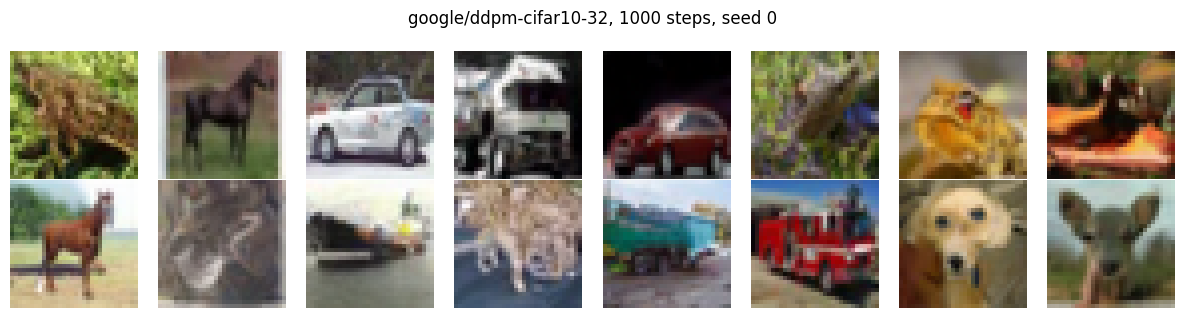

In [32]:
from diffusers import DDPMPipeline
pipe = DDPMPipeline.from_pretrained("google/ddpm-cifar10-32").to(device)
gen = torch.Generator(device=device).manual_seed(SEED)
if device == "cuda": torch.cuda.synchronize()
t0 = time.time()
imgs = pipe(batch_size=16, num_inference_steps=TRY_STEPS, generator=gen).images
if device == "cuda": torch.cuda.synchronize()
RESULTS["try_seconds"] = round(time.time() - t0, 1)
RESULTS["try_steps"] = TRY_STEPS
print(f"16 張 × {TRY_STEPS} 步：{RESULTS['try_seconds']} 秒")
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for a, im in zip(ax.flat, imgs):
    a.imshow(im); a.axis("off")
plt.suptitle(f"google/ddpm-cifar10-32, {TRY_STEPS} steps, seed {SEED}")
plt.tight_layout(); plt.savefig("try_pretrained.png", dpi=120); plt.show()
del pipe

## B. 往前加噪：把一張衣服一步一步弄髒
- 一共 **T＝1000** 步。第 t 步加多少雜訊由 **β_t**（beta，雜訊排程）決定：從 0.0001 慢慢變大到 0.02。
- **ᾱ_t**（alpha bar）：到第 t 步為止，原圖還「留下」多少。不用真的一步一步加，可以**一行直接跳到第 t 步**：

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$$

讀作：「第 t 步的圖 ＝ 原圖乘上 √ᾱ_t，加上雜訊乘上 √(1−ᾱ_t)」。ε（epsilon）是標準常態的隨機雜訊。

訓練圖 60000 張；一張 (1, 32, 32)


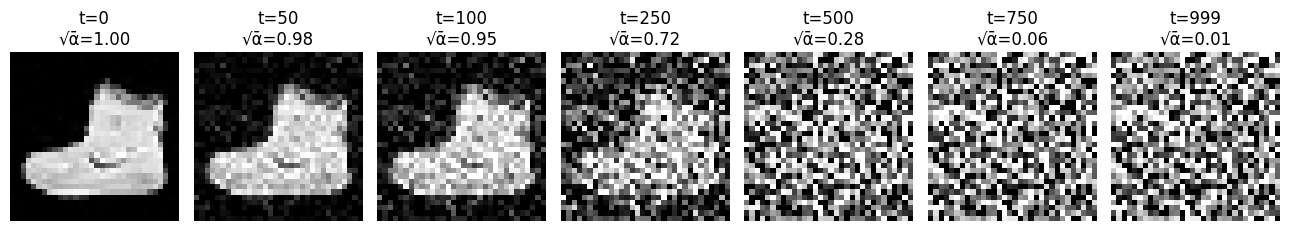

t=   0  √ᾱ_t（原圖佔）1.000   √(1−ᾱ_t)（雜訊佔）0.010
t=  50  √ᾱ_t（原圖佔）0.985   √(1−ᾱ_t)（雜訊佔）0.173
t= 100  √ᾱ_t（原圖佔）0.946   √(1−ᾱ_t)（雜訊佔）0.324
t= 250  √ᾱ_t（原圖佔）0.722   √(1−ᾱ_t)（雜訊佔）0.692
t= 500  √ᾱ_t（原圖佔）0.279   √(1−ᾱ_t)（雜訊佔）0.960
t= 750  √ᾱ_t（原圖佔）0.057   √(1−ᾱ_t)（雜訊佔）0.998
t= 999  √ᾱ_t（原圖佔）0.006   √(1−ᾱ_t)（雜訊佔）1.000


In [33]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms

tf = transforms.Compose([transforms.Pad(2), transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])  # 28→32，−1～1
train_ds = datasets.FashionMNIST("data/download", train=True, download=True, transform=tf)
test_ds = datasets.FashionMNIST("data/download", train=False, download=True, transform=tf)
print("訓練圖", len(train_ds), "張；一張", tuple(train_ds[0][0].shape))

T = 1000
betas = torch.linspace(1e-4, 0.02, T)            # β_t：每一步加的雜訊量（線性排程，DDPM 論文的設定）
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, dim=0)         # ᾱ_t：原圖還剩多少
sqrt_ab, sqrt_1mab = alpha_bar.sqrt(), (1 - alpha_bar).sqrt()

def q_sample(x0, t, eps):
    """一行跳到第 t 步：x_t = √ᾱ_t · x0 + √(1−ᾱ_t) · ε"""
    return sqrt_ab.to(x0.device)[t].view(-1, 1, 1, 1) * x0 + sqrt_1mab.to(x0.device)[t].view(-1, 1, 1, 1) * eps

STRIP_T = [0, 50, 100, 250, 500, 750, 999]
x0 = train_ds[0][0][None]                         # 第 0 張：一隻短靴
g = torch.Generator().manual_seed(SEED)
eps = torch.randn(x0.shape, generator=g)
fig, ax = plt.subplots(1, len(STRIP_T), figsize=(13, 2.4))
for a, t in zip(ax, STRIP_T):
    a.imshow(q_sample(x0, torch.tensor([t]), eps)[0, 0], cmap="gray", vmin=-1, vmax=1); a.axis("off")
    a.set_title(f"t={t}\n√ᾱ={sqrt_ab[t]:.2f}")
plt.tight_layout(); plt.savefig("forward_strip.png", dpi=120); plt.show()
for t in STRIP_T:
    print(f"t={t:4d}  √ᾱ_t（原圖佔）{sqrt_ab[t]:.3f}   √(1−ᾱ_t)（雜訊佔）{sqrt_1mab[t]:.3f}")
RESULTS["strip"] = {t: [round(sqrt_ab[t].item(), 3), round(sqrt_1mab[t].item(), 3)] for t in STRIP_T}

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(sqrt_ab, label="√ᾱ_t  (image)"); plt.plot(sqrt_1mab, label="√(1−ᾱ_t)  (noise)")
plt.plot(betas / betas.max(), "--", label="β_t (scaled to max 1)")
plt.xlabel("t"); plt.legend(); plt.title("linear schedule, T=1000"); plt.tight_layout(); plt.savefig("schedule.png", dpi=120); plt.show()
half = int((sqrt_ab < sqrt_1mab).nonzero()[0])
print(f"從 t＝{half} 開始，雜訊的比例就大於原圖")
RESULTS["noise_wins_at"] = half

**練習（投影片「練習：第幾步就認不出來了？」）**：改下面的 `t`，找出「已經看不出是哪一種衣服」的最小 t，記下它的 √ᾱ_t。

In [ ]:
t = 300   # 改這裡：0～999
plt.figure(figsize=(2, 2)); plt.imshow(q_sample(x0, torch.tensor([t]), eps)[0, 0], cmap="gray", vmin=-1, vmax=1)
plt.axis("off"); plt.title(f"t={t}  √ᾱ={sqrt_ab[t]:.2f}"); plt.show()

## C. 去噪網路：D2-2 的 U-Net ＋ 時間
- 輸入：髒的圖 x_t `[B,1,32,32]` **和** 步數 t `[B]`；輸出：**預測的雜訊** ε̂ `[B,1,32,32]`（和輸入同樣大小）
- 網路要知道「現在有多髒」：把 t 變成一條 sin／cos 向量（**時間嵌入**），加到每一個區塊裡
- 編碼、解碼、跳接（`torch.cat`）都和 D2-2 一樣

In [ ]:
def time_embedding(t, dim=64):
    """t [B] → [B, dim]：不同頻率的 sin、cos。相近的 t 得到相近的向量。"""
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)

class Block(nn.Module):
    """D2-2 的 block（兩次 3×3 卷積），中間加上「時間」"""
    def __init__(self, cin, cout, tdim=64):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())
        self.time = nn.Linear(tdim, cout)              # 時間向量 → 每個通道加一個數
        self.conv2 = nn.Sequential(nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())
    def forward(self, x, temb):
        h = self.conv1(x)
        h = h + self.time(temb)[:, :, None, None]      # [B, cout] → [B, cout, 1, 1]，加到每個像素
        return self.conv2(h)

class TinyUNet(nn.Module):
    def __init__(self, c=32, tdim=64):
        super().__init__()
        self.tdim = tdim
        self.tmlp = nn.Sequential(nn.Linear(tdim, tdim), nn.ReLU(), nn.Linear(tdim, tdim))
        self.enc1, self.enc2, self.enc3 = Block(1, c), Block(c, 2 * c), Block(2 * c, 4 * c)
        self.mid = Block(4 * c, 8 * c)
        self.pool = nn.MaxPool2d(2)
        self.up3, self.dec3 = nn.ConvTranspose2d(8 * c, 4 * c, 2, stride=2), Block(8 * c, 4 * c)
        self.up2, self.dec2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2), Block(4 * c, 2 * c)
        self.up1, self.dec1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2), Block(2 * c, c)
        self.head = nn.Conv2d(c, 1, 1)                  # 每個像素一個數：預測的雜訊

    def forward(self, x, t, show=False):
        temb = self.tmlp(time_embedding(t, self.tdim))
        e1 = self.enc1(x, temb)                         # 32 × 32
        e2 = self.enc2(self.pool(e1), temb)             # 16 × 16
        e3 = self.enc3(self.pool(e2), temb)             # 8 × 8
        b = self.mid(self.pool(e3), temb)               # 4 × 4（瓶頸）
        d3 = self.dec3(torch.cat([self.up3(b), e3], 1), temb)
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1), temb)
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1), temb)
        out = self.head(d1)
        if show:
            for name, v in [("x_t", x), ("t", t), ("time_embedding", temb), ("e1", e1), ("e2", e2), ("e3", e3),
                            ("b（瓶頸）", b), ("d1", d1), ("out＝預測的雜訊", out)]:
                print(f"{name:16s}", tuple(v.shape))
        return out

model = TinyUNet().to(device)
with torch.no_grad():
    model(torch.randn(8, 1, 32, 32, device=device), torch.randint(0, T, (8,), device=device), show=True)
RESULTS["params"] = sum(p.numel() for p in model.parameters())
print("參數", f"{RESULTS['params']:,}")

In [ ]:
te = time_embedding(torch.arange(T)).numpy()
plt.figure(figsize=(7, 2.6)); plt.imshow(te.T, aspect="auto", cmap="RdBu", interpolation="nearest")
plt.xlabel("t"); plt.ylabel("dimension"); plt.title("time embedding: each column is one t"); plt.colorbar()
plt.tight_layout(); plt.savefig("time_embedding.png", dpi=120); plt.show()

## D. 訓練：預測雜訊
每一批：隨機挑一個 t、隨機產生雜訊 ε、一行做出 x_t，叫網路猜 ε。損失＝**猜的雜訊和真的雜訊的 MSE**。
沒有鑑別器、沒有兩個優化器：迴圈和 D1-3 一樣，只是「題目」是程式自己出的。

In [ ]:
CKPT = "ddpm_fmnist.pt"
CKPT_URLS = [f"https://raw.githubusercontent.com/LinTzuYu0925/GAI_tutorial/{b}/11-ddpm-from-scratch/materials/ddpm_fmnist.pt"
             for b in ("main", "build-d3")]
# 整個資料集一次放進 GPU（60,000 × 32 × 32 只有約 250 MB），每一批直接切，不用 DataLoader
X_all = F.pad(train_ds.data, (2, 2, 2, 2)).float().div(127.5).sub(1)[:, None]      # 和上面的 tf 一樣：補邊、−1～1
X_all = (X_all if TRAIN_SUBSET is None else X_all[:TRAIN_SUBSET]).to(device)
BATCH = 128
steps_per_epoch = len(X_all) // BATCH
opt = torch.optim.Adam(model.parameters(), lr=2e-4)
sab, s1mab = sqrt_ab.to(device), sqrt_1mab.to(device)
hist = []

if USE_CKPT:
    for url in CKPT_URLS:
        if os.system(f"mkdir -p data/download && wget -q -O data/download/{CKPT} {url}") == 0: break
    model.load_state_dict({k: v.float() for k, v in torch.load("data/download/" + CKPT, map_location=device).items()})
    print("載入講師的檢查點，跳過訓練")
else:
    if device == "cuda": torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for idx in torch.randperm(len(X_all), device=device)[:steps_per_epoch * BATCH].split(BATCH):
            x0 = X_all[idx]
            t = torch.randint(0, T, (len(x0),), device=device)
            eps = torch.randn_like(x0)
            x_t = sab[t].view(-1, 1, 1, 1) * x0 + s1mab[t].view(-1, 1, 1, 1) * eps
            loss = F.mse_loss(model(x_t, t), eps)
            opt.zero_grad(); loss.backward(); opt.step()
            hist.append(loss.item())
        print(f"epoch {epoch:2d}  loss {np.mean(hist[-steps_per_epoch:]):.4f}  ({time.time()-t0:.0f}s)")
    RESULTS["train_seconds"] = round(time.time() - t0)
    RESULTS["epochs"] = EPOCHS
    RESULTS["final_loss"] = round(float(np.mean(hist[-steps_per_epoch:])), 4)
    if device == "cuda":
        RESULTS["train_vram_gb"] = round(torch.cuda.max_memory_allocated() / 1e9, 2)
        print(f"訓練 VRAM 峰值 {RESULTS['train_vram_gb']} GB")
    torch.save({k: v.half().cpu() for k, v in model.state_dict().items()}, CKPT)

    plt.figure(figsize=(7, 2.8)); plt.plot(hist, alpha=0.4, label="each step")
    k = 50; plt.plot(np.convolve(hist, np.ones(k) / k, mode="valid"), label=f"mean of {k} steps")
    plt.xlabel("step"); plt.ylabel("MSE (noise)"); plt.ylim(0, max(0.2, min(1.0, hist[0])))
    plt.legend(); plt.title("diffusion loss: one network, one plain MSE"); plt.tight_layout(); plt.savefig("loss.png", dpi=120); plt.show()

## E. 取樣：從純雜訊走 1000 步回來
每一步：網路猜出雜訊 ε̂，從 x_t **扣掉一點點**，得到 x_{t−1}；除了最後一步，再加回一點新的隨機雜訊。

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\hat\varepsilon\Big) + \sqrt{\beta_t}\,z$$

In [ ]:
@torch.no_grad()
def sample(n, seed=SEED, keep=()):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(n, 1, 32, 32, device=device, generator=g)          # x_T：純雜訊
    kept = {}
    for t in reversed(range(T)):
        tt = torch.full((n,), t, device=device, dtype=torch.long)
        eps_hat = model(x, tt)
        mean = (x - betas[t] / sqrt_1mab[t] * eps_hat) / alphas[t].sqrt()
        x = mean + betas[t].sqrt() * torch.randn(x.shape, device=device, generator=g) if t > 0 else mean
        if t in keep: kept[t] = x[:8].cpu()
    return x.clamp(-1, 1).cpu(), kept

if device == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
t0 = time.time()
samples, kept = sample(64, keep=(999, 750, 500, 250, 100, 0))
if device == "cuda": torch.cuda.synchronize()
RESULTS["ddpm_1000_seconds_64"] = round(time.time() - t0, 1)
if device == "cuda": RESULTS["sample_vram_gb"] = round(torch.cuda.max_memory_allocated() / 1e9, 2)
print(f"64 張 × 1000 步：{RESULTS['ddpm_1000_seconds_64']} 秒")

fig, ax = plt.subplots(4, 16, figsize=(14, 3.8))
for a, im in zip(ax.flat, samples): a.imshow(im[0], cmap="gray", vmin=-1, vmax=1); a.axis("off")
plt.suptitle(f"our tiny DDPM: 64 samples, 1000 steps, seed {SEED}"); plt.tight_layout(); plt.savefig("samples.png", dpi=120); plt.show()

fig, ax = plt.subplots(4, 6, figsize=(9, 6.2))
for c, t in enumerate([999, 750, 500, 250, 100, 0]):
    for r in range(4): ax[r, c].imshow(kept[t][r, 0], cmap="gray", vmin=-1, vmax=1); ax[r, c].axis("off")
    ax[0, c].set_title(f"t={t}")
plt.tight_layout(); plt.savefig("reverse_strip.png", dpi=120); plt.show()

**多樣性：和 D3-1 的 DCGAN 比**。用 D3-1 同一個量法：32 張圖兩兩之間的平均像素距離（28 × 28、−1～1）。越小 → 越常畫同樣的東西。

In [ ]:
def mean_pairwise(x):
    f = x.reshape(len(x), -1)
    return (torch.cdist(f, f).sum() / (len(x) * (len(x) - 1))).item()

crop = lambda x: x[:, :, 2:30, 2:30]                  # 32 → 28，和 D3-1 一樣大
real32 = crop(torch.stack([train_ds[i][0] for i in range(32)]))
RESULTS["pairwise_real"] = round(mean_pairwise(real32), 2)
RESULTS["pairwise_ddpm"] = round(mean_pairwise(crop(samples[:32])), 2)
print(f"真實 32 張：{RESULTS['pairwise_real']:.2f}")
print(f"我們的 DDPM 32 張：{RESULTS['pairwise_ddpm']:.2f}")
print("D3-1 的 DCGAN（講師 T4 實跑，epoch 20）：22.08；真實圖片 22.90")
RESULTS["fg_real"] = round((real32 > -0.5).float().mean().item(), 3)
RESULTS["fg_ddpm"] = round((crop(samples[:32]) > -0.5).float().mean().item(), 3)
print(f"衣物佔畫面的比例（像素 > −0.5）：真實 {RESULTS['fg_real']:.1%}｜DDPM {RESULTS['fg_ddpm']:.1%}")

**兩兩距離只是一個數字**：圖比較瘦、比較暗，距離也會變小。換一個量法：訓練一個小分類器（D1-3 的 CNN，1 個 epoch），
數一數 64 張生成圖各被判成哪一類。10 類都有 → 多樣；擠在少數幾類 → 崩塌。

In [ ]:
CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
clf = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Flatten(), nn.Linear(64 * 8 * 8, 10)).to(device)
opt_c = torch.optim.Adam(clf.parameters(), lr=1e-3)
Y_all = train_ds.targets.to(device)
for idx in torch.randperm(len(train_ds), device=device).split(128):
    loss_c = F.cross_entropy(clf(F.pad(train_ds.data[idx.cpu()], (2, 2, 2, 2)).float().div(127.5).sub(1)[:, None].to(device)), Y_all[idx])
    opt_c.zero_grad(); loss_c.backward(); opt_c.step()
clf.eval()
with torch.no_grad():
    X_test = F.pad(test_ds.data, (2, 2, 2, 2)).float().div(127.5).sub(1)[:, None].to(device)
    RESULTS["clf_test_acc"] = round((clf(X_test).argmax(1).cpu() == test_ds.targets).float().mean().item(), 3)
    cnt_ddpm = torch.bincount(clf(samples.to(device)).argmax(1).cpu(), minlength=10)
    cnt_real = torch.bincount(test_ds.targets[:64], minlength=10)
RESULTS["classes_ddpm"] = cnt_ddpm.tolist(); RESULTS["classes_real64"] = cnt_real.tolist()
print(f"分類器測試準確率 {RESULTS['clf_test_acc']:.1%}")
print(f"64 張 DDPM 樣本出現 {(cnt_ddpm > 0).sum().item()} 類；64 張真圖出現 {(cnt_real > 0).sum().item()} 類")
plt.figure(figsize=(9, 2.8)); xs = np.arange(10)
plt.bar(xs - 0.2, cnt_real, 0.4, label="64 real (test set)"); plt.bar(xs + 0.2, cnt_ddpm, 0.4, label="64 DDPM samples")
plt.xticks(xs, CLASSES, rotation=20); plt.ylabel("count"); plt.legend(); plt.title("which classes does the DDPM draw? (small CNN classifier)")
plt.tight_layout(); plt.savefig("class_counts.png", dpi=120); plt.show()

## F. 少走幾步：DDIM
同一個網路、不用重新訓練，換一個**排程器**（scheduler）：`diffusers` 的 `DDIMScheduler` 可以只走 50、20、10 步。
先猜：步數少 10 倍，時間會少幾倍？圖會變差多少？

In [ ]:
from diffusers import DDIMScheduler

@torch.no_grad()
def sample_ddim(n, steps, seed=SEED):
    model.eval()
    sched = DDIMScheduler(num_train_timesteps=T, beta_start=1e-4, beta_end=0.02, beta_schedule="linear",
                          clip_sample=False)   # 預設 True 會把每一步估出的 x̂₀ 裁到 −1～1；小模型在雜訊很多的前幾步估得很不準，裁掉反而出錯（講師 T4 實跑發現）
    sched.set_timesteps(steps)
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(n, 1, 32, 32, device=device, generator=g)
    for t in sched.timesteps:
        eps_hat = model(x, torch.full((n,), int(t), device=device, dtype=torch.long))
        x = sched.step(eps_hat, t, x).prev_sample           # 一次跳一大步
    return x.clamp(-1, 1).cpu()

STEPS = [250, 100, 50, 20, 10]
ddim = {}
for s in STEPS:
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time(); ddim[s] = sample_ddim(64, s)
    if device == "cuda": torch.cuda.synchronize()
    RESULTS[f"ddim_{s}_seconds_64"] = round(time.time() - t0, 2)
    RESULTS[f"pairwise_ddim_{s}"] = round(mean_pairwise(crop(ddim[s][:32])), 2)
print(f"{'步數':>6s} {'64 張秒數':>10s} {'兩兩距離':>8s}")
print(f"{'DDPM 1000':>6s} {RESULTS['ddpm_1000_seconds_64']:10.2f} {RESULTS['pairwise_ddpm']:8.2f}")
for s in STEPS:
    print(f"{'DDIM ' + str(s):>9s} {RESULTS[f'ddim_{s}_seconds_64']:10.2f} {RESULTS[f'pairwise_ddim_{s}']:8.2f}")

fig, ax = plt.subplots(len(STEPS), 1, figsize=(12, 1.5 * len(STEPS)))
for a, s in zip(ax, STEPS):
    a.imshow(torch.cat(list(ddim[s][:16, 0]), 1), cmap="gray", vmin=-1, vmax=1); a.axis("off")
    a.set_title(f"DDIM {s} steps: {RESULTS[f'ddim_{s}_seconds_64']} s for 64 images", loc="left")
plt.tight_layout(); plt.savefig("ddim_steps.png", dpi=120); plt.show()

## G. 風險：是不是「背下來」的？
對每一張生成圖，在 60,000 張訓練圖裡找**最像的一張**（像素距離最小）。
參考值：拿 16 張**沒參加訓練**的測試圖做同樣的事。生成圖的距離如果明顯比參考值小很多 → 可能是背下來的。

In [ ]:
@torch.no_grad()
def nearest(q):
    best_d, best_i = torch.full((len(q),), float("inf")), torch.zeros(len(q), dtype=torch.long)
    qf = crop(q).reshape(len(q), -1).to(device)
    for start in range(0, len(train_ds), 5000):
        xb = crop(torch.stack([train_ds[i][0] for i in range(start, min(start + 5000, len(train_ds)))]))
        d = torch.cdist(qf, xb.reshape(len(xb), -1).to(device)).cpu()
        m, i = d.min(1)
        upd = m < best_d
        best_d[upd], best_i[upd] = m[upd], i[upd] + start
    return best_d, best_i

d_gen, i_gen = nearest(samples[:16])
d_test, _ = nearest(torch.stack([test_ds[i][0] for i in range(16)]))
RESULTS["nn_gen_median"] = round(d_gen.median().item(), 2)
RESULTS["nn_test_median"] = round(d_test.median().item(), 2)
RESULTS["nn_gen_min"] = round(d_gen.min().item(), 2)
print(f"生成圖 → 最近的訓練圖：中位數 {RESULTS['nn_gen_median']:.2f}，最小 {RESULTS['nn_gen_min']:.2f}")
print(f"測試圖 → 最近的訓練圖：中位數 {RESULTS['nn_test_median']:.2f}（參考值）")

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for j in range(8):
    ax[0, j].imshow(samples[j, 0], cmap="gray", vmin=-1, vmax=1); ax[0, j].set_title(f"d={d_gen[j]:.1f}")
    ax[1, j].imshow(train_ds[int(i_gen[j])][0][0], cmap="gray", vmin=-1, vmax=1)
    ax[0, j].axis("off"); ax[1, j].axis("off")
for r, name in enumerate(["generated", "nearest train"]):
    ax[r, 0].text(-0.08, 0.5, name, transform=ax[r, 0].transAxes, rotation=90, ha="right", va="center")
plt.tight_layout(); plt.savefig("nearest.png", dpi=120); plt.show()

## 存檔
所有數字存成 `results.json`，連同圖片和檢查點打包成 `lab11_outputs.zip`（在 Colab 會自動下載）。

In [ ]:
import zipfile
if device == "cuda": RESULTS["gpu"] = torch.cuda.get_device_name(0)
RESULTS.update(torch=torch.__version__, diffusers=diffusers.__version__, python=platform.python_version(), seed=SEED)
json.dump(RESULTS, open("results.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print(json.dumps(RESULTS, ensure_ascii=False))
with zipfile.ZipFile("lab11_outputs.zip", "w") as z:
    for f in sorted(os.listdir(".")):
        if f.endswith((".png", ".json")) or f == CKPT: z.write(f)
try:
    from google.colab import files
    files.download("lab11_outputs.zip")
except ImportError:
    print("不在 Colab：lab11_outputs.zip 已存在目前資料夾")